In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

Saving credit_risk_dataset.csv to credit_risk_dataset.csv


In [ ]:

# Membaca dataset
credit_risk_dataset = next(iter(uploaded))
df = pd.read_csv(credit_risk_dataset)

# Pemeriksaan awal
print("Ukuran dataset:", df.shape)

display(df.head())

print("\nInformasi kolom:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDistribusi target:")
print(df["loan_status"].value_counts())

print("\nProporsi target (%):")
print((df["loan_status"].value_counts(normalize=True) * 100).round(2))

Ukuran dataset: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4



Informasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB

Missing valu

,Missing Count,Missing (%)
loan_int_rate,3116,9.56
person_emp_length,895,2.75


,Jumlah,Persentase (%)
Non-default (0),25473,78.18
Default (1),7108,21.82


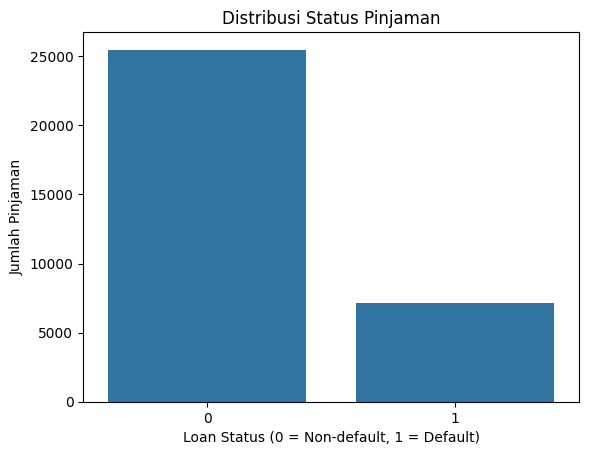

Jumlah baris duplikat: 165


In [ ]:

# 1. Persentase missing values per kolom
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing (%)": (df.isnull().mean() * 100).round(2)
})

display(
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing Count", ascending=False)
)

# 2. Distribusi target
target_summary = pd.DataFrame({
    "Jumlah": df["loan_status"].value_counts().sort_index(),
    "Persentase (%)": (
        df["loan_status"].value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
})

target_summary.index = ["Non-default (0)", "Default (1)"]
display(target_summary)

# 3. Visualisasi distribusi target
sns.countplot(data=df, x="loan_status")
plt.title("Distribusi Status Pinjaman")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Jumlah Pinjaman")
plt.show()

# 4. Pemeriksaan duplikasi
print("Jumlah baris duplikat:", df.duplicated().sum())

In [ ]:

# Menampilkan contoh baris duplikat
duplicate_rows = df[df.duplicated(keep=False)]

print("Jumlah baris dalam kelompok duplikat:",
      len(duplicate_rows))

display(duplicate_rows.head(10))

# Memeriksa apakah ada kolom ID
print("Daftar kolom:")
print(df.columns.tolist())

Jumlah baris dalam kelompok duplikat: 330


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
14,23,115000,RENT,2.0,EDUCATION,A,35000,7.90,0,0.30,N,4
238,22,183000,MORTGAGE,3.0,EDUCATION,A,1000,NaN,0,0.01,N,2
252,24,85000,RENT,5.0,MEDICAL,B,25000,10.62,0,0.29,N,4
591,26,20000,MORTGAGE,5.0,MEDICAL,A,4800,5.99,0,0.24,N,3
740,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
817,22,22000,OWN,1.0,DEBTCONSOLIDATION,D,8500,15.05,0,0.39,N,4
920,26,50000,RENT,10.0,PERSONAL,B,18950,NaN,1,0.38,N,3
1094,22,24449,OWN,2.0,VENTURE,B,1800,11.89,0,0.07,N,4
1142,25,60000,RENT,3.0,PERSONAL,A,17000,6.91,0,0.28,N,2
1453,23,20400,RENT,2.0,MEDICAL,A,1200,7.90,0,0.06,N,2


Daftar kolom:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']


In [ ]:

# Menghapus baris yang identik pada seluruh kolom
df = df.drop_duplicates().copy()

# Memeriksa hasil
print("Jumlah data setelah deduplikasi:", len(df))
print("Jumlah duplikat tersisa:", df.duplicated().sum())

# Memeriksa kembali missing values
display(
    df.isnull().sum()[df.isnull().sum() > 0]
)

Jumlah data setelah deduplikasi: 32416
Jumlah duplikat tersisa: 0


,0
person_emp_length,887
loan_int_rate,3095


,loan_grade,Total_Loan,Total_Default,Default_Rate
0,A,10703,1066,9.96
1,B,10387,1695,16.32
2,C,6438,1336,20.75
3,D,3620,2138,59.06
4,E,963,621,64.49
5,F,241,170,70.54
6,G,64,63,98.44


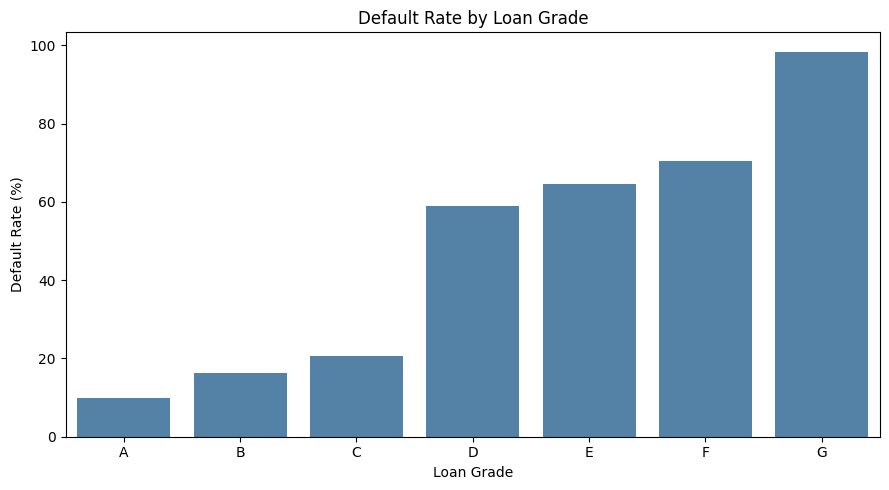

In [ ]:

grade_summary = (
    df.groupby("loan_grade")
      .agg(
          Total_Loan=("loan_status", "count"),
          Total_Default=("loan_status", "sum"),
          Default_Rate=("loan_status", "mean")
      )
      .reset_index()
)

grade_summary["Default_Rate"] *= 100

display(grade_summary.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=grade_summary,
    x="loan_grade",
    y="Default_Rate",
    color="steelblue"
)

plt.title("Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()

In [ ]:
intent_summary = (
    df.groupby("loan_intent")
      .agg(
          Total_Loan=("loan_status", "count"),
          Total_Default=("loan_status", "sum"),
          Default_Rate=("loan_status", "mean")
      )
      .reset_index()
)

intent_summary["Default_Rate"] *= 100

display(
    intent_summary
    .sort_values("Default_Rate", ascending=False)
    .round(2)
)

,loan_intent,Total_Loan,Total_Default,Default_Rate
0,DEBTCONSOLIDATION,5189,1488,28.68
3,MEDICAL,6042,1617,26.76
2,HOMEIMPROVEMENT,3594,940,26.15
4,PERSONAL,5498,1094,19.90
1,EDUCATION,6411,1106,17.25
5,VENTURE,5682,844,14.85


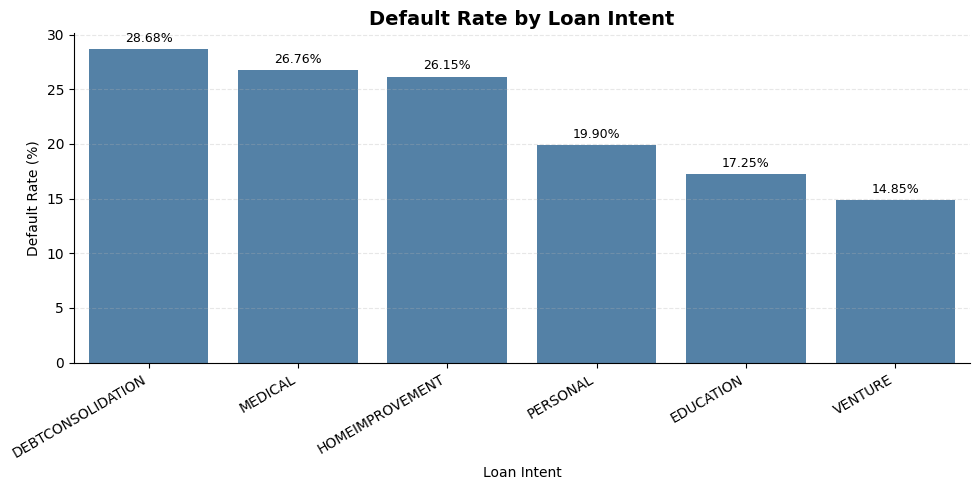

In [ ]:

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=intent_summary,
    x="loan_intent",
    y="Default_Rate",
    color="steelblue",
    order=intent_summary.sort_values(
        "Default_Rate", ascending=False
    )["loan_intent"]
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=9
    )

plt.title("Default Rate by Loan Intent", fontsize=14, fontweight="bold")
plt.xlabel("Loan Intent")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

### Analisis Default Rate Berdasarkan Tujuan Pinjaman

Hasil analisis menunjukkan bahwa tingkat gagal bayar bervariasi berdasarkan tujuan pengajuan pinjaman. Kategori *debt consolidation* memiliki default rate tertinggi sebesar 28,68%, diikuti oleh *medical* sebesar 26,76% dan *home improvement* sebesar 26,15%. Sementara itu, kategori *venture* memiliki default rate terendah sebesar 14,85%.

Perbedaan ini menunjukkan adanya hubungan antara tujuan pinjaman dan tingkat gagal bayar pada dataset yang dianalisis. Dalam konteks manajemen risiko kredit, variabel `loan_intent` dapat dipertimbangkan sebagai salah satu fitur dalam pemodelan prediksi risiko kredit. Namun, hasil ini belum menunjukkan hubungan sebab-akibat dan perlu dianalisis bersama variabel lain, seperti pendapatan, jumlah pinjaman, suku bunga, dan loan grade.


In [ ]:
ownership_summary = (
    df.groupby("person_home_ownership")
      .agg(
          Total_Loan=("loan_status", "count"),
          Total_Default=("loan_status", "sum"),
          Default_Rate=("loan_status", "mean")
      )
      .reset_index()
)

ownership_summary["Default_Rate"] *= 100

display(
    ownership_summary
    .sort_values("Default_Rate", ascending=False)
    .round(2)
)

,person_home_ownership,Total_Loan,Total_Default,Default_Rate
3,RENT,16378,5177,31.61
1,OTHER,106,33,31.13
0,MORTGAGE,13369,1687,12.62
2,OWN,2563,192,7.49


### Analisis Default Rate Berdasarkan Status Kepemilikan Tempat Tinggal

Hasil analisis menunjukkan bahwa tingkat gagal bayar berbeda berdasarkan status kepemilikan tempat tinggal. Kategori RENT memiliki default rate tertinggi di antara kategori dengan jumlah observasi yang besar, yaitu 31,61%, sedangkan kategori OWN memiliki default rate terendah sebesar 7,49%. Kategori MORTGAGE memiliki default rate sebesar 12,62%.

Temuan ini menunjukkan adanya hubungan antara status kepemilikan tempat tinggal dan tingkat gagal bayar pada dataset yang dianalisis. Dalam konteks manajemen risiko kredit, variabel `person_home_ownership` berpotensi menjadi salah satu fitur dalam model prediksi risiko kredit. Namun, hubungan ini tidak membuktikan sebab-akibat dan perlu dianalisis bersama variabel lain, seperti pendapatan, masa kerja, jumlah pinjaman, suku bunga, dan loan grade. Kategori OTHER juga perlu dievaluasi lebih lanjut karena memiliki jumlah observasi yang relatif kecil.


In [ ]:
income_summary = (
    df.assign(
        Income_Group=pd.qcut(
            df["person_income"],
            q=5,
            duplicates="drop"
        )
    )
    .groupby("Income_Group", observed=True)
    .agg(
        Total_Loan=("loan_status", "count"),
        Total_Default=("loan_status", "sum"),
        Default_Rate=("loan_status", "mean")
    )
    .reset_index()
)

income_summary["Default_Rate"] *= 100

display(income_summary.round(2))

,Income_Group,Total_Loan,Total_Default,Default_Rate
0,"(3999.999, 35000.0]",6591,2855,43.32
1,"(35000.0, 49000.0]",6508,1532,23.54
2,"(49000.0, 63000.0]",6367,1163,18.27
3,"(63000.0, 86000.0]",6486,947,14.60
4,"(86000.0, 6000000.0]",6464,592,9.16


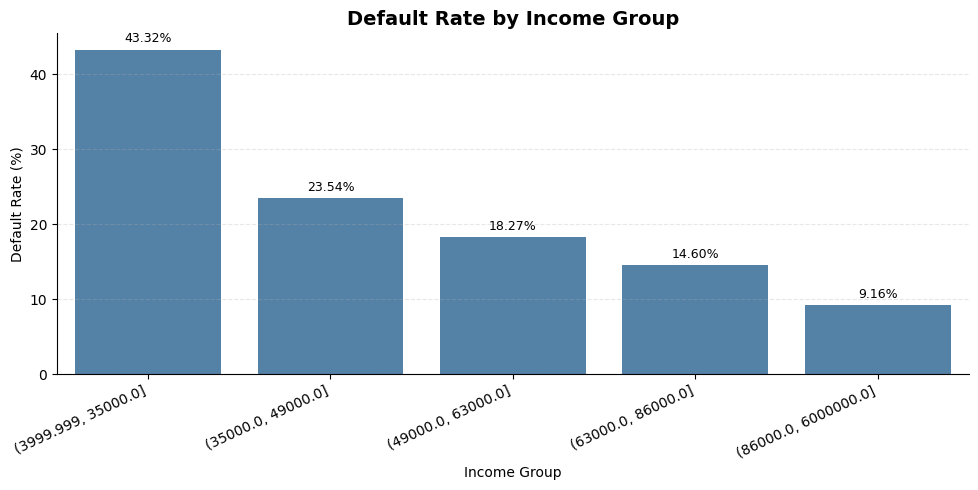

In [ ]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=income_summary,
    x="Income_Group",
    y="Default_Rate",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=9
    )

plt.title("Default Rate by Income Group", fontsize=14, fontweight="bold")
plt.xlabel("Income Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

### Analisis Default Rate Berdasarkan Pendapatan Peminjam

Hasil analisis menunjukkan pola hubungan negatif antara pendapatan peminjam dan tingkat gagal bayar pada dataset yang digunakan. Kelompok dengan pendapatan terendah memiliki default rate sebesar 43,32%, sedangkan kelompok dengan pendapatan tertinggi memiliki default rate sebesar 9,16%. Dengan demikian, terdapat selisih sebesar 34,16 poin persentase antara kedua kelompok tersebut.

Temuan ini mengindikasikan bahwa pendapatan dapat menjadi salah satu variabel yang relevan dalam analisis risiko kredit. Peminjam dengan pendapatan lebih rendah mungkin memiliki ruang finansial yang lebih terbatas untuk memenuhi kewajiban pembayaran, meskipun hal tersebut belum dapat disimpulkan secara langsung dari analisis ini. Oleh karena itu, variabel `person_income` perlu dievaluasi bersama faktor lain, seperti jumlah pinjaman, suku bunga, rasio pinjaman terhadap pendapatan, dan loan grade, sebelum digunakan dalam pengambilan keputusan risiko kredit.


In [ ]:
interest_summary = (
    df.assign(
        Interest_Group=pd.qcut(
            df["loan_int_rate"],
            q=5,
            duplicates="drop"
        )
    )
    .groupby("Interest_Group", observed=True)
    .agg(
        Total_Loan=("loan_status", "count"),
        Total_Default=("loan_status", "sum"),
        Default_Rate=("loan_status", "mean")
    )
    .reset_index()
)

interest_summary["Default_Rate"] *= 100

display(interest_summary.round(2))

,Interest_Group,Total_Loan,Total_Default,Default_Rate
0,"(5.419, 7.51]",5978,524,8.77
1,"(7.51, 10.25]",5951,802,13.48
2,"(10.25, 11.86]",5746,955,16.62
3,"(11.86, 13.92]",5787,1199,20.72
4,"(13.92, 23.22]",5859,2968,50.66


### Analisis Default Rate Berdasarkan Suku Bunga Pinjaman

Hasil analisis menunjukkan pola hubungan positif antara suku bunga pinjaman dan tingkat gagal bayar pada dataset yang digunakan. Kelompok dengan suku bunga terendah memiliki default rate sebesar 8,77%, sedangkan kelompok dengan suku bunga tertinggi memiliki default rate sebesar 50,66%. Selisih tersebut mencapai 41,89 poin persentase.

Temuan ini mengindikasikan bahwa variabel `loan_int_rate` berpotensi relevan dalam mengidentifikasi profil risiko kredit. Meskipun demikian, hubungan ini tidak dapat langsung diartikan sebagai hubungan sebab-akibat karena penetapan suku bunga dapat dipengaruhi oleh karakteristik dan tingkat risiko peminjam. Oleh karena itu, variabel ini perlu dianalisis bersama faktor lain dan dievaluasi melalui pemodelan prediktif.


In [ ]:
loan_percent_summary = (
    df.assign(
        Loan_Percent_Group=pd.qcut(
            df["loan_percent_income"],
            q=5,
            duplicates="drop"
        )
    )
    .groupby("Loan_Percent_Group", observed=True)
    .agg(
        Total_Loan=("loan_status", "count"),
        Total_Default=("loan_status", "sum"),
        Default_Rate=("loan_status", "mean")
    )
    .reset_index()
)

loan_percent_summary["Default_Rate"] *= 100

display(loan_percent_summary.round(2))

,Loan_Percent_Group,Total_Loan,Total_Default,Default_Rate
0,"(-0.001, 0.08]",7535,863,11.45
1,"(0.08, 0.12]",5558,693,12.47
2,"(0.12, 0.18]",7297,1107,15.17
3,"(0.18, 0.25]",5776,1110,19.22
4,"(0.25, 0.83]",6250,3316,53.06


### Analisis Default Rate Berdasarkan Loan-to-Income Ratio

Hasil analisis menunjukkan bahwa tingkat gagal bayar cenderung meningkat seiring bertambahnya proporsi pinjaman terhadap pendapatan peminjam. Kelompok dengan rasio pinjaman terhadap pendapatan hingga 8% memiliki default rate sebesar 11,45%, sedangkan kelompok dengan rasio di atas 25% memiliki default rate sebesar 53,06%.

Perbedaan sebesar 41,61 poin persentase ini mengindikasikan bahwa `loan_percent_income` berpotensi menjadi fitur yang relevan dalam pemodelan risiko kredit. Rasio yang lebih tinggi dapat mencerminkan beban pinjaman yang lebih besar relatif terhadap pendapatan. Namun, temuan ini merupakan hubungan deskriptif pada dataset dan tidak membuktikan hubungan sebab-akibat.


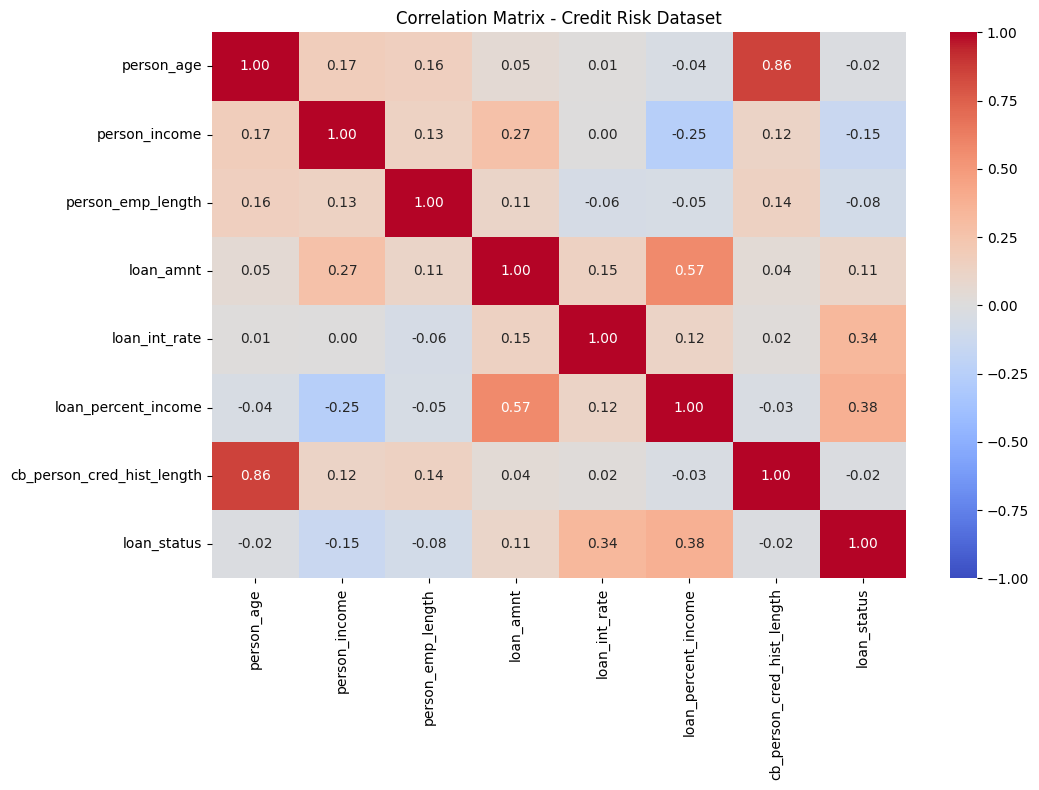

In [ ]:
numeric_cols = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "loan_status"
]

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix - Credit Risk Dataset")
plt.tight_layout()
plt.show()

In [ ]:
# Distribusi target
print("Distribusi loan_status:")
print(df["loan_status"].value_counts())

print("\nProporsi target (%):")
print(
    (df["loan_status"].value_counts(normalize=True) * 100)
    .round(2)
)

# Tipe data dan missing values
print("\nInformasi dataset:")
df.info()

print("\nMissing values:")
display(
    df.isnull().sum()
       .sort_values(ascending=False)
       .to_frame("Missing Values")
)

Distribusi loan_status:
loan_status
0    25327
1     7089
Name: count, dtype: int64

Proporsi target (%):
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
Index: 32416 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32416 non-null  int64  
 1   person_income               32416 non-null  int64  
 2   person_home_ownership       32416 non-null  object 
 3   person_emp_length           31529 non-null  float64
 4   loan_intent                 32416 non-null  object 
 5   loan_grade                  32416 non-null  object 
 6   loan_amnt                   32416 non-null  int64  
 7   loan_int_rate               29321 non-null  float64
 8   loan_status                 32416 non-null  int64  
 9   loan_percent_income         32416 non-null  float64
 10  cb_person_defa

,Missing Values
loan_int_rate,3095
person_emp_length,887
person_income,0
person_age,0
person_home_ownership,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_status,0
loan_percent_income,0


In [ ]:
# 1. Periksa duplikasi yang tersisa
print("Jumlah duplikasi:", df.duplicated().sum())

# 2. Statistik deskriptif variabel numerik
numeric_cols = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

display(df[numeric_cols].describe().T.round(2))

# 3. Periksa nilai ekstrem yang perlu ditinjau
print("Usia di atas 100 tahun:", (df["person_age"] > 100).sum())
print("Pendapatan <= 0:", (df["person_income"] <= 0).sum())
print("Masa kerja negatif:", (df["person_emp_length"] < 0).sum())
print("Jumlah pinjaman <= 0:", (df["loan_amnt"] <= 0).sum())

Jumlah duplikasi: 0


,count,mean,std,min,25%,50%,75%,max
person_age,32416.0,27.75,6.35,20.00,23.00,26.00,30.00,144.00
person_income,32416.0,66091.64,62015.58,4000.00,38542.00,55000.00,79218.00,6000000.00
person_emp_length,31529.0,4.79,4.15,0.00,2.00,4.00,7.00,123.00
loan_amnt,32416.0,9593.85,6322.73,500.00,5000.00,8000.00,12250.00,35000.00
loan_int_rate,29321.0,11.02,3.24,5.42,7.90,10.99,13.47,23.22
loan_percent_income,32416.0,0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32416.0,5.81,4.06,2.00,3.00,4.00,8.00,30.00


Usia di atas 100 tahun: 5
Pendapatan <= 0: 0
Masa kerja negatif: 0
Jumlah pinjaman <= 0: 0


In [ ]:
# Periksa usia ekstrem
display(
    df.loc[df["person_age"] > 100]
    .sort_values("person_age", ascending=False)
)

# Periksa masa kerja ekstrem
display(
    df.loc[df["person_emp_length"] > 50]
    .sort_values("person_emp_length", ascending=False)
)

# Periksa pendapatan ekstrem
display(
    df.loc[df["person_income"] > 1_000_000]
    .sort_values("person_income", ascending=False)
)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25
30049,42,2039784,RENT,0.0,VENTURE,C,8450,12.29,0,0.00,Y,15
32546,60,1900000,MORTGAGE,5.0,PERSONAL,A,1500,NaN,0,0.00,N,21
32497,63,1782000,RENT,13.0,EDUCATION,C,12025,14.27,0,0.01,N,30
31924,44,1440000,MORTGAGE,7.0,DEBTCONSOLIDATION,A,6400,7.40,0,0.00,N,15
31922,47,1362000,MORTGAGE,9.0,VENTURE,A,6600,7.74,0,0.00,N,17
17833,32,1200000,MORTGAGE,1.0,VENTURE,A,12000,7.51,0,0.01,N,8
29119,36,1200000,OWN,16.0,MEDICAL,A,10000,6.54,0,0.01,N,11
29120,40,1200000,MORTGAGE,1.0,MEDICAL,A,10000,NaN,0,0.01,N,16


In [ ]:
# Salin dataset agar perubahan lebih terkontrol
df = df.copy()

# Hitung data tidak wajar sebelum penanganan
print("Usia di atas 100 tahun:", (df["person_age"] > 100).sum())
print("Masa kerja di atas 50 tahun:", (df["person_emp_length"] > 50).sum())

# Hapus baris dengan usia tidak wajar
df = df[df["person_age"] <= 100].copy()

# Ubah masa kerja yang tidak wajar menjadi missing value
df.loc[df["person_emp_length"] > 50, "person_emp_length"] = np.nan

# Periksa hasil
print("\nJumlah baris setelah penanganan:", len(df))
print("Usia di atas 100 tahun:", (df["person_age"] > 100).sum())
print("Masa kerja di atas 50 tahun:",
      (df["person_emp_length"] > 50).sum())
print("Missing value per kolom:")
print(df.isnull().sum())

Usia di atas 100 tahun: 5
Masa kerja di atas 50 tahun: 2

Jumlah baris setelah penanganan: 32411
Usia di atas 100 tahun: 0
Masa kerja di atas 50 tahun: 0
Missing value per kolom:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              889
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3094
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


In [ ]:

# Membuat kategori proporsi pinjaman terhadap pendapatan
df["loan_to_income_category"] = pd.cut(
    df["loan_percent_income"],
    bins=[-float("inf"), 0.10, 0.20, 0.30, float("inf")],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Very High"
    ]
)

# Memeriksa hasil kategori
print(df["loan_to_income_category"].value_counts().sort_index())

# Melihat contoh hasil
display(
    df[["loan_percent_income", "loan_to_income_category"]].head(10)
)

loan_to_income_category
Low          10427
Moderate     11999
High          6166
Very High     3819
Name: count, dtype: int64


,loan_percent_income,loan_to_income_category
0,0.59,Very High
1,0.10,Low
2,0.57,Very High
3,0.53,Very High
4,0.55,Very High
5,0.25,High
6,0.45,Very High
7,0.44,Very High
8,0.42,Very High
9,0.16,Moderate


In [ ]:

# Menghitung jumlah pinjaman dan default rate per kategori
risk_by_income_category = (
    df.groupby("loan_to_income_category", observed=False)
      .agg(
          total_loans=("loan_status", "count"),
          total_defaults=("loan_status", "sum"),
          default_rate=("loan_status", "mean")
      )
      .reset_index()
)

# Mengubah default rate menjadi persentase
risk_by_income_category["default_rate"] *= 100

display(risk_by_income_category.round(2))

,loan_to_income_category,total_loans,total_defaults,default_rate
0,Low,10427,1226,11.76
1,Moderate,11999,1815,15.13
2,High,6166,1358,22.02
3,Very High,3819,2690,70.44


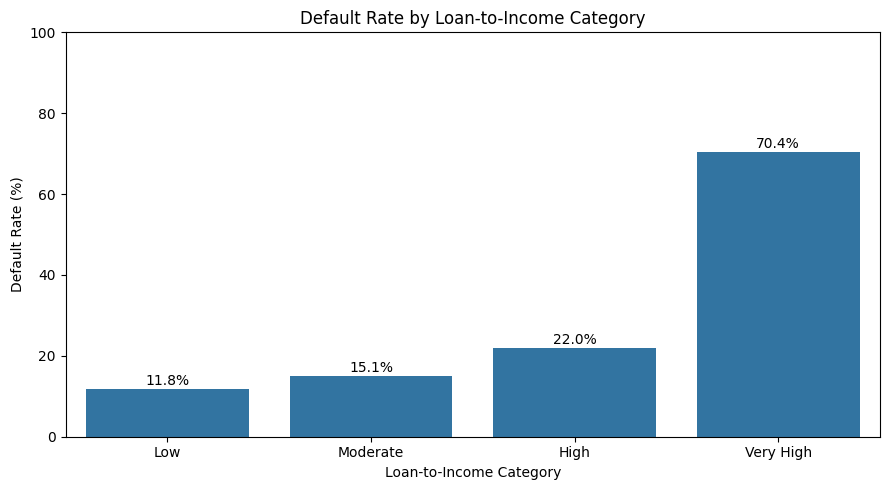

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=risk_by_income_category,
    x="loan_to_income_category",
    y="default_rate"
)

plt.title("Default Rate by Loan-to-Income Category")
plt.xlabel("Loan-to-Income Category")
plt.ylabel("Default Rate (%)")
plt.ylim(0, 100)

for i, row in risk_by_income_category.iterrows():
    plt.text(
        i,
        row["default_rate"] + 1,
        f'{row["default_rate"]:.1f}%',
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:

# Menentukan target
target = "loan_status"

# Menentukan fitur
X = df.drop(
    columns=["loan_status", "loan_to_income_category"]
)

y = df["loan_status"]

print("Jumlah data:", len(df))
print("Jumlah fitur:", X.shape[1])
print("\nDistribusi target:")
print(y.value_counts())
print("\nDistribusi target (%):")
print((y.value_counts(normalize=True) * 100).round(2))

Jumlah data: 32411
Jumlah fitur: 11

Distribusi target:
loan_status
0    25322
1     7089
Name: count, dtype: int64

Distribusi target (%):
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

print("\nProporsi target training (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nProporsi target testing (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Jumlah data training: 25928
Jumlah data testing: 6483

Proporsi target training (%):
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64

Proporsi target testing (%):
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Memisahkan fitur numerik dan kategorikal
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Fitur numerik:", numeric_features)
print("\nFitur kategorikal:", categorical_features)

# Pipeline fitur numerik
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline fitur kategorikal
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Menggabungkan preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessor berhasil dibuat.")

Fitur numerik: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

Fitur kategorikal: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

Preprocessor berhasil dibuat.


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Membuat pipeline model
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Melatih model dengan data training
logistic_model.fit(X_train, y_train)

print("Model Logistic Regression berhasil dilatih.")

Model Logistic Regression berhasil dilatih.


Accuracy : 0.8704
Precision: 0.779
Recall   : 0.5691
F1-score : 0.6577
ROC-AUC  : 0.8668

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.89      0.95      0.92      5065
     Default       0.78      0.57      0.66      1418

    accuracy                           0.87      6483
   macro avg       0.83      0.76      0.79      6483
weighted avg       0.86      0.87      0.86      6483



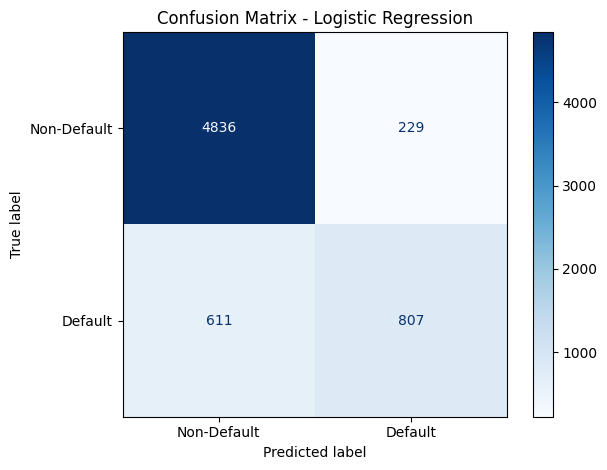

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Prediksi kelas dan probabilitas default
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Menghitung metrik evaluasi
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Default", "Default"],
    zero_division=0
))

# Visualisasi confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Non-Default", "Default"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.5, 0.4, 0.3, 0.2]

results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.5,0.7790,0.5691,0.6577
1,0.4,0.7086,0.6432,0.6743
2,0.3,0.6294,0.7151,0.6695
3,0.2,0.5216,0.7842,0.6265


In [ ]:

# Logistic Regression dengan class weighting
logistic_balanced = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Melatih model
logistic_balanced.fit(X_train, y_train)

# Prediksi
y_pred_balanced = logistic_balanced.predict(X_test)
y_prob_balanced = logistic_balanced.predict_proba(X_test)[:, 1]

# Evaluasi
print("Accuracy :", round(
    accuracy_score(y_test, y_pred_balanced), 4
))
print("Precision:", round(
    precision_score(y_test, y_pred_balanced, zero_division=0), 4
))
print("Recall   :", round(
    recall_score(y_test, y_pred_balanced, zero_division=0), 4
))
print("F1-score :", round(
    f1_score(y_test, y_pred_balanced, zero_division=0), 4
))
print("ROC-AUC  :", round(
    roc_auc_score(y_test, y_prob_balanced), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Non-Default", "Default"],
    zero_division=0
))

Accuracy : 0.8124
Precision: 0.5509
Recall   : 0.7708
F1-score : 0.6426
ROC-AUC  : 0.8686

Classification Report:
              precision    recall  f1-score   support

 Non-Default       0.93      0.82      0.87      5065
     Default       0.55      0.77      0.64      1418

    accuracy                           0.81      6483
   macro avg       0.74      0.80      0.76      6483
weighted avg       0.85      0.81      0.82      6483



In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest - Class Balanced")
print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_rf), 4))

Random Forest - Class Balanced
Accuracy : 0.9338
Precision: 0.9732
Recall   : 0.7172
F1-score : 0.8258
ROC-AUC  : 0.9314


In [ ]:

from sklearn.inspection import permutation_importance
import pandas as pd

# Mengukur kontribusi prediktif fitur pada test set
perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
}).sort_values(
    "Importance_Mean",
    ascending=False
)

display(feature_importance.round(4))

,Feature,Importance_Mean,Importance_Std
8,loan_percent_income,0.0761,0.0024
2,person_home_ownership,0.0695,0.0047
5,loan_grade,0.0539,0.0024
1,person_income,0.0469,0.0019
4,loan_intent,0.0430,0.0026
7,loan_int_rate,0.0176,0.0012
9,cb_person_default_on_file,0.0104,0.0013
3,person_emp_length,0.0091,0.0007
0,person_age,0.0080,0.0006
6,loan_amnt,0.0074,0.0014


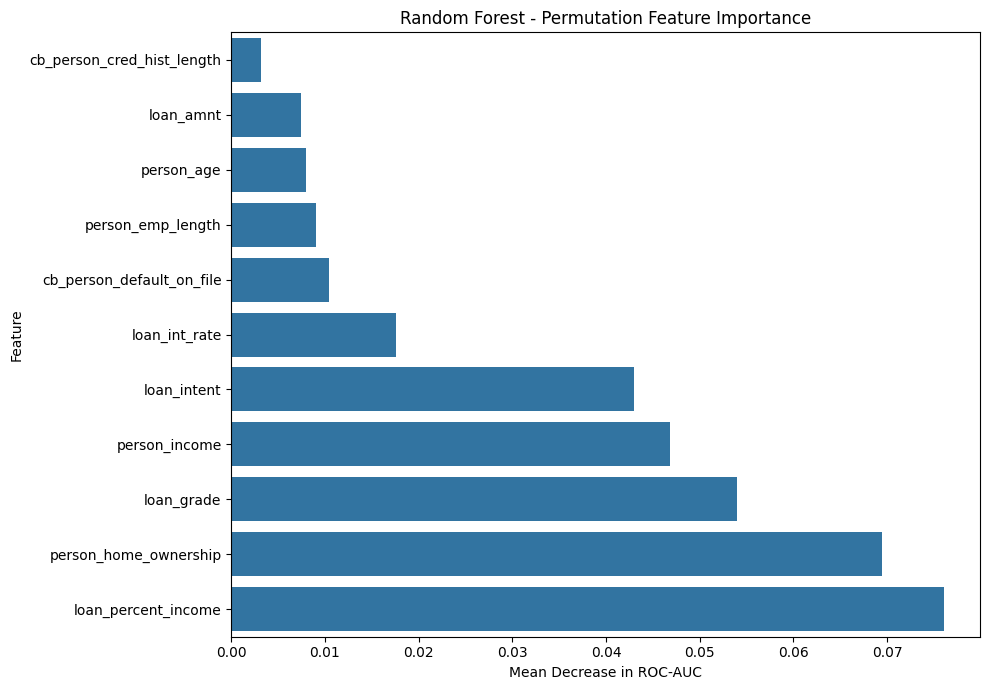

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

importance_plot = feature_importance.sort_values(
    "Importance_Mean",
    ascending=True
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_plot,
    x="Importance_Mean",
    y="Feature"
)

plt.title("Random Forest - Permutation Feature Importance")
plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
df.to_csv("credit_risk_cleaned.csv", index=False)
import pandas as pd

risk_results = X_test.copy()

risk_results["Actual_Status"] = y_test
risk_results["Predicted_Status"] = rf_model.predict(X_test)
risk_results["Default_Probability"] = rf_model.predict_proba(X_test)[:, 1]

risk_results["Actual_Label"] = risk_results["Actual_Status"].map({
    0: "Non-Default",
    1: "Default"
})

risk_results["Predicted_Label"] = risk_results["Predicted_Status"].map({
    0: "Non-Default",
    1: "Default"
})

risk_results.to_csv("credit_risk_predictions.csv", index=False)
feature_importance.to_csv(
    "credit_risk_feature_importance.csv",
    index=False
)
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression Balanced",
        "Random Forest Balanced"
    ],
    "Accuracy": [0.8704, 0.8124, 0.9338],
    "Precision": [0.7790, 0.5509, 0.9732],
    "Recall": [0.5691, 0.7708, 0.7172],
    "F1_Score": [0.6577, 0.6426, 0.8258],
    "ROC_AUC": [0.8668, 0.8686, 0.9314]
})

model_comparison.to_csv("credit_risk_model_comparison.csv", index=False)